# TIỀN XỬ LÝ DỮ LIỆU

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score

df = pd.read_csv('../../Lab01/2/sp500_yahoo.csv')
df = df[df['Volume'] > 0].dropna().reset_index(drop=True)

df['Range'] = (df['High'] - df['Low']) / df['Open']
df['Mid_Diff'] = ((df['High'] + df['Low']) / 2 - df['Open']) / df['Open']
df['Log_Vol'] = np.log1p(df['Volume'])

features = ['Open', 'High', 'Low', 'Range', 'Mid_Diff', 'Log_Vol']
X = df[features].values
y = np.where(df['Close'].values > df['Open'].values, 1, -1)

split_idx = int(0.8 * len(X))
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# HUẤN LUYỆN MÔ HÌNH

In [2]:
start_sk = time.time()
clf = LinearSVC(C=10.0, loss='hinge', max_iter=5000, random_state=42)
clf.fit(X_train_scaled, y_train)
time_sk = time.time() - start_sk

y_pred_sk = clf.predict(X_test_scaled)
prec_sk = precision_score(y_test, y_pred_sk)
rec_sk = recall_score(y_test, y_pred_sk)
f1_sk = f1_score(y_test, y_pred_sk)

print(f'Thoi gian: {time_sk:.4f}s')
print(f'Precision: {prec_sk:.4f}')
print(f'Recall:    {rec_sk:.4f}')
print(f'F1-Score:  {f1_sk:.4f}')

Thoi gian: 0.1057s
Precision: 0.9266
Recall:    0.6061
F1-Score:  0.7329


C:\Users\ACER\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


# SO SÁNH VỚI MÔ HÌNH TỰ CÀI ĐẶT

In [3]:
def train_svm_sgd(X, y, C=10.0, lr=0.005, epochs=60, batch_size=128):
    np.random.seed(42)
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    for _ in range(epochs):
        idx = np.random.permutation(n_samples)
        X_s, y_s = X[idx], y[idx]
        for i in range(0, n_samples, batch_size):
            Xb, yb = X_s[i:i+batch_size], y_s[i:i+batch_size]
            mask = yb * (Xb @ w + b) < 1
            dw = w - C * np.mean(yb[mask, None] * Xb[mask], axis=0) if np.any(mask) else w
            db = -C * np.mean(yb[mask]) if np.any(mask) else 0.0
            w -= lr * dw
            b -= lr * db
    return w, b

start_sgd = time.time()
w_sgd, b_sgd = train_svm_sgd(X_train_scaled, y_train)
time_sgd = time.time() - start_sgd

y_pred_sgd = np.where(X_test_scaled @ w_sgd + b_sgd >= 0, 1, -1)
prec_sgd = precision_score(y_test, y_pred_sgd)
rec_sgd = recall_score(y_test, y_pred_sgd)
f1_sgd = f1_score(y_test, y_pred_sgd)

comp_df = pd.DataFrame({
    'Mo hinh': ['NumPy SGD (Bai 3)', 'Scikit-Learn LinearSVC (Bai 4)'],
    'Precision': [prec_sgd, prec_sk],
    'Recall': [rec_sgd, rec_sk],
    'F1-Score': [f1_sgd, f1_sk],
    'Thoi gian (s)': [time_sgd, time_sk]
})
print(comp_df.to_string(index=False))

                       Mo hinh  Precision   Recall  F1-Score  Thoi gian (s)
             NumPy SGD (Bai 3)   0.874871 0.816042  0.844433       0.201725
Scikit-Learn LinearSVC (Bai 4)   0.926579 0.606148  0.732869       0.105720


# VẼ ĐỒ THỊ

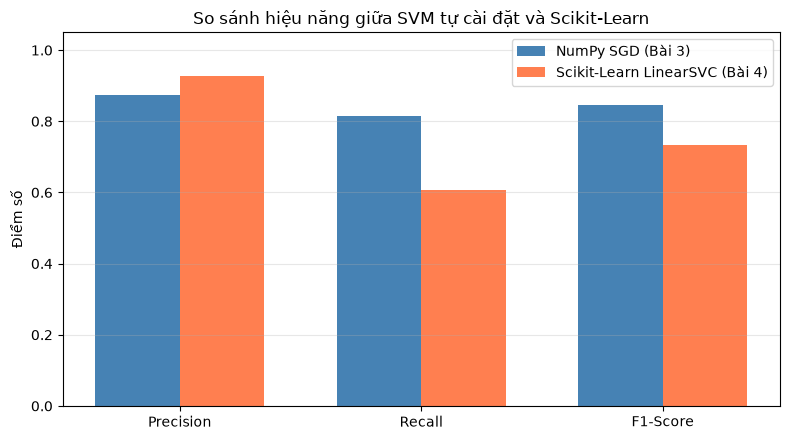

In [4]:
metrics = ['Precision', 'Recall', 'F1-Score']
sgd_vals = [prec_sgd, rec_sgd, f1_sgd]
sk_vals = [prec_sk, rec_sk, f1_sk]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width/2, sgd_vals, width, label='NumPy SGD (Bài 3)', color='steelblue')
ax.bar(x + width/2, sk_vals, width, label='Scikit-Learn LinearSVC (Bài 4)', color='coral')

ax.set_ylabel('Điểm số')
ax.set_title('So sánh hiệu năng giữa SVM tự cài đặt và Scikit-Learn')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()